# 01. Data audit

**Goal.** Look at the Effort dataset before any model does: what is in it, what is wrong with it, and what that means for the
experiments. Nothing here is fitted or tuned. The target, success criteria and rules are in [PROTOCOL.md](PROTOCOL.md).

**Task.** Predict the Effort score (0-1) of one student in one sprint from `E_CC`, `E_LOC_net_capped`, `E_FC`, `E_CT`, `E_RD`.
The ground truth is the rater's `(R_avg - 1) / 4` on the five Effort criteria, available for 20 real records.

**Note on decisions.** Several decisions below come from looking at all the data. Because every group is a test group once, that cannot
be avoided, so each such decision is confirmed in cross-validation in notebook 03 and not argued from test results.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("training").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import FEATURES, load, log_signed, md_table

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

d = load()
real = d[d.source == "real"].copy()
syn = d[d.source == "synthetic"].copy()
gold = real[real.label_source == "rater"].copy()
active = real[real.E_CC > 0].copy()
print(d.shape)
d.head(3).T

(744, 31)


,0,1,2
record_id,T01-S1-STU-014,T01-S1-STU-003,T01-S1-STU-021
source,real,real,real
group,A,A,A
team_id,T01,T01,T01
sprint_id,T01-S1,T01-S1,T01-S1
student_id,STU-014,STU-003,STU-021
team_size,4.0,4.0,4.0
profile,NaN,NaN,NaN
parents,NaN,NaN,NaN
parents_in_group,NaN,NaN,NaN


## 1. Size and structure

In [2]:
sizes = pd.DataFrame({
    "real records": real.groupby("group").size(),
    "rated (ground truth)": gold.groupby("group").size(),
    "no commits": real[real.E_CC == 0].groupby("group").size(),
    "students": real.groupby("group").student_id.nunique(),
    "teams": real.groupby("group").team_id.nunique(),
    "synthetic": syn.groupby("group").size(),
}).fillna(0).astype(int)
sizes.loc["total"] = sizes.sum()
sizes

,real records,rated (ground truth),no commits,students,teams,synthetic
group,,,,,,
A,71,7,22,8,6,294
B,28,4,5,5,3,146
C,21,4,5,5,2,66
D,16,3,1,4,2,69
E,8,2,4,4,1,25
total,144,20,37,26,14,600


Groups join teams that share a student (16 of 26 students are in more than one team), so no student is in two groups. This is the unit
for every split, and it is why the per-group student and team counts add up to the totals.

In [3]:
# a student must belong to exactly one group
per_student = real.groupby("student_id").group.nunique()
assert (per_student == 1).all(), "a student appears in more than one group"
print("every student belongs to exactly one group")
print("students in more than one team:", int((real.groupby('student_id').team_id.nunique() > 1).sum()), "of", real.student_id.nunique())

every student belongs to exactly one group
students in more than one team: 16 of 26


## 2. Missing, impossible and duplicate values

In [4]:
cols = FEATURES + ["effort_label"]
checks = {
    "missing values (features and label)": int(d[cols].isna().sum().sum()),
    "duplicate record ids": int(d.record_id.duplicated().sum()),
    "labels outside 0-1": int(((d.effort_label < 0) | (d.effort_label > 1)).sum()),
    "real records with negative net lines": int((real.E_LOC_net_capped < 0).sum()),
    "synthetic records with negative net lines": int((syn.E_LOC_net_capped < 0).sum()),
    "real: commits but no files": int(((real.E_CC > 0) & (real.E_FC == 0)).sum()),
    "synthetic: commits but no files": int(((syn.E_CC > 0) & (syn.E_FC == 0)).sum()),
    "real: no commits but code or files": int(((real.E_CC == 0) & ((real.E_LOC_net_capped != 0) | (real.E_FC != 0))).sum()),
    "synthetic: no commits but code or files": int(((syn.E_CC == 0) & ((syn.E_LOC_net_capped != 0) | (syn.E_FC != 0))).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
missing values (features and label),0
duplicate record ids,0
labels outside 0-1,0
real records with negative net lines,3
synthetic records with negative net lines,43
real: commits but no files,0
synthetic: commits but no files,0
real: no commits but code or files,0
synthetic: no commits but code or files,0


In [5]:
real[real.E_LOC_net_capped < 0][["record_id", "E_CC", "E_LOC_added", "E_LOC_deleted", "E_LOC_net_capped", "E_FC"]]

,record_id,E_CC,E_LOC_added,E_LOC_deleted,E_LOC_net_capped,E_FC
32,T03-S3-STU-011,1,40,139,-99,3
42,T04-S2-STU-010,1,197,358,-161,21
68,T07-S2-STU-001,7,8149,11789,-746,80


Negative net lines in real records are sprints that deleted more code than they added (clean-up and refactoring). They are legitimate and
kept. The synthetic negatives are blends of those and are far more frequent than in the real data (compare the two counts above), so
synthetic rows with negative net lines are worth watching in the tuning notebook.

## 3. Feature distributions

In [6]:
rows = []
for c in FEATURES:
    x = real[c].astype(float)
    rows.append({"feature": c, "zero share": (x == 0).mean(), "median": x.median(), "90th pct": x.quantile(.9), "max": x.max(),
                 "skew": x.skew(), "skew after log": pd.Series(log_signed(x)).skew()})
pd.DataFrame(rows).set_index("feature").round(2)

,zero share,median,90th pct,max,skew,skew after log
feature,,,,,,
E_CC,0.26,4.0,21.0,91.0,3.09,0.19
E_LOC_net_capped,0.26,868.5,3783.6,9832.0,1.79,-0.99
E_FC,0.26,21.0,80.0,255.0,2.33,-0.48
E_CT,0.38,1.0,4.0,10.0,1.34,0.16
E_RD,0.91,0.0,0.0,12.0,5.04,3.67


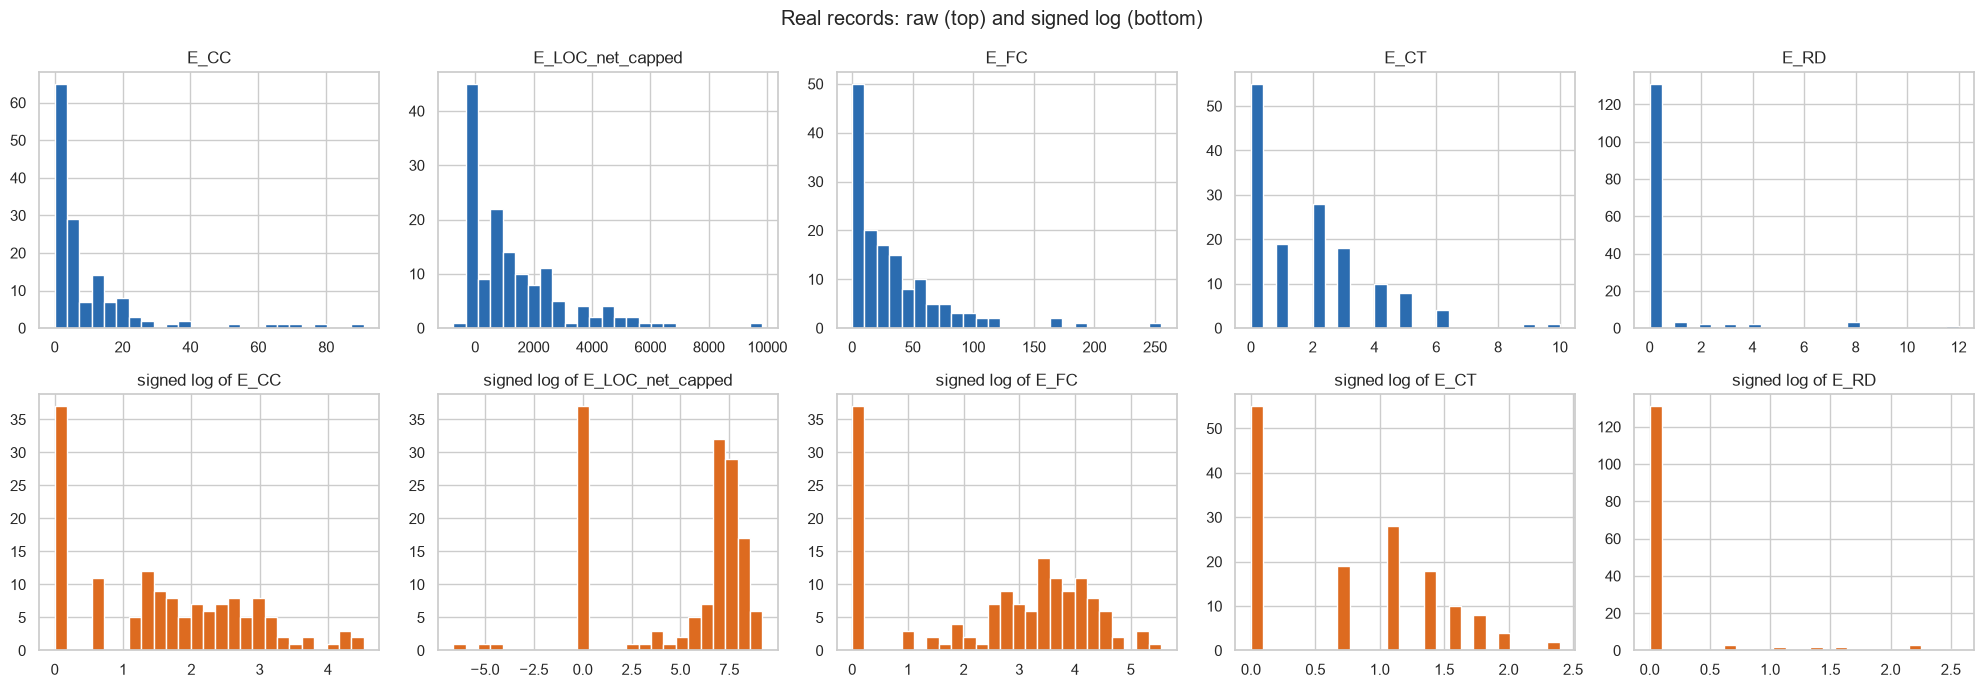

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(FEATURES):
    axes[0, i].hist(real[c], bins=25, color="#2b6cb0")
    axes[0, i].set_title(c)
    axes[1, i].hist(log_signed(real[c]), bins=25, color="#dd6b20")
    axes[1, i].set_title("signed log of " + c)
fig.suptitle("Real records: raw (top) and signed log (bottom)")
fig.tight_layout()
plt.show()

Counts are heavily skewed, which motivates the log transform for linear models. `E_RD` is zero for almost every record, so it carries
almost no information; decision for notebook 03: drop it or redefine it from merged-PR activity.

## 4. Overlap between features

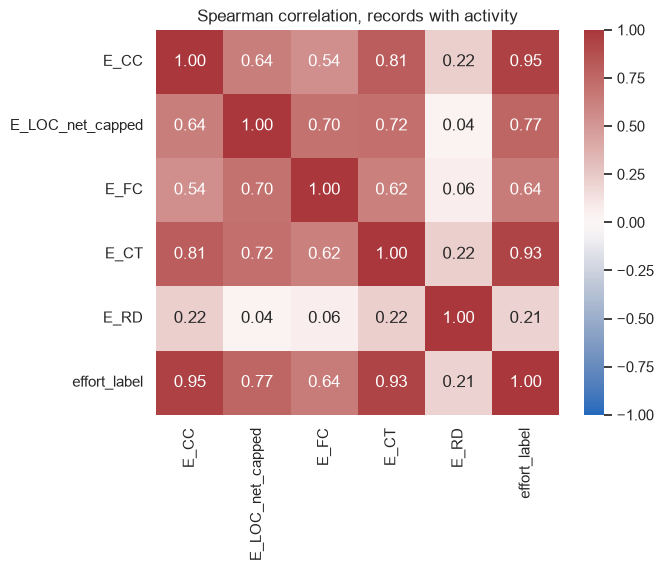

In [8]:
corr = active[FEATURES + ["effort_label"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation, records with activity")
plt.show()

`E_CC` (commits) and `E_CT` (tasks done) move together, and the label follows them closely. `E_CT` comes from the reconstructed Scrum board,
so it is not an independent measurement; notebook 03 compares models with and without it.

## 5. Zero-commit records

In [9]:
zero = real[real.E_CC == 0]
print(f"{len(zero)} of {len(real)} real records ({len(zero)/len(real):.0%}) have no commits")
print("label of rated zero-commit records:", sorted(gold[gold.E_CC == 0].rater_effort.tolist()))
by_team = real.groupby("team_id").apply(lambda g: (g.E_CC == 0).mean(), include_groups=False).sort_values(ascending=False)
by_team.round(2).to_frame("share with no commits").T

37 of 144 real records (26%) have no commits
label of rated zero-commit records: [0.0, 0.0, 0.0]


team_id,T02,T05,T06,T12,T13,T01,T11,T09,T10,T03,T08,T04,T07,T14
share with no commits,0.62,0.56,0.5,0.5,0.31,0.25,0.25,0.25,0.25,0.13,0.08,0.0,0.0,0.0


A quarter of the data is "did nothing this sprint". Whether to treat that as a fixed rule (zero commits means zero effort) or let the model
learn it is a design decision for notebook 03. In either case, every result is reported for all records and for records with activity only,
because the zero records make an overall error look better than it is.

## 6. The labelled records

count    20.000
mean      0.390
std       0.256
min       0.000
25%       0.138
50%       0.450
75%       0.612
max       0.750

distinct label values: [np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.65), np.float64(0.7), np.float64(0.75)]


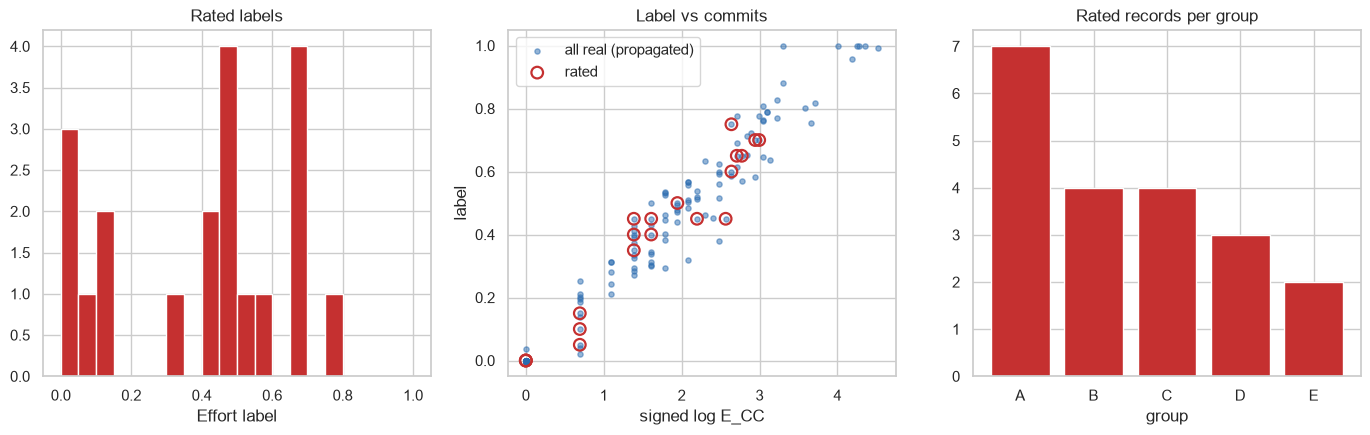

In [10]:
print(gold.rater_effort.describe().round(3).to_string())
print()
print("distinct label values:", sorted(gold.rater_effort.unique()))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(gold.rater_effort, bins=np.linspace(0, 1, 21), color="#c53030")
axes[0].set(title="Rated labels", xlabel="Effort label")
axes[1].scatter(log_signed(real.E_CC), real.effort_label, s=14, alpha=.5, label="all real (propagated)", color="#2b6cb0")
axes[1].scatter(log_signed(gold.E_CC), gold.rater_effort, s=70, facecolor="none", edgecolor="#c53030", lw=1.6, label="rated")
axes[1].set(title="Label vs commits", xlabel="signed log E_CC", ylabel="label"); axes[1].legend()
axes[2].bar(sizes.index[:-1], sizes["rated (ground truth)"][:-1], color="#c53030")
axes[2].set(title="Rated records per group", xlabel="group")
plt.show()

In [11]:
active_cc = active.E_CC
print("active real records:", len(active), "| commits quantiles:", active_cc.quantile([.5, .9, 1]).to_dict())
print("rated records with more than 30 commits:", int((gold.E_CC > 30).sum()), "| active real records with more than 30:", int((active.E_CC > 30).sum()))
print("rated records:", len(gold), "| highest label:", gold.rater_effort.max(), "| real records scoring above 0.8:", int((real.effort_score > 0.8).sum()))

active real records: 107 | commits quantiles: {0.5: 7.0, 0.9: 24.80000000000001, 1.0: 91.0}
rated records with more than 30 commits: 0 | active real records with more than 30: 9
rated records: 20 | highest label: 0.75 | real records scoring above 0.8: 12


The ground truth has no examples above 0.75 and none with many commits, while the data contains heavy contributors. Every result must
say it applies to the range the labels cover; the model's behaviour above it is only checked by the invariant tests in notebook 07.

## 7. Team size

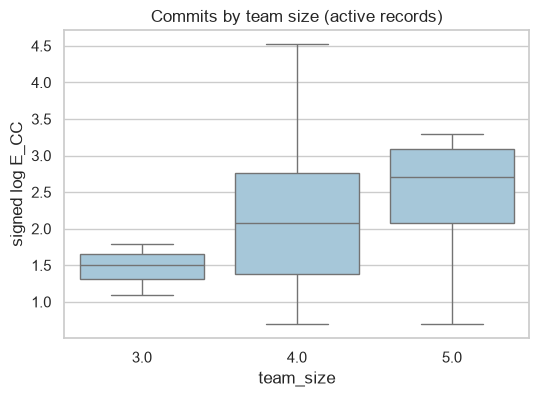

,records,median_commits,median_lines
team_size,,,
3.0,4,3.5,1091.5
4.0,90,7.0,1546.5
5.0,13,14.0,1310.0


In [12]:
t = active.groupby("team_size").agg(records=("record_id", "size"), median_commits=("E_CC", "median"), median_lines=("E_LOC_net_capped", "median"))
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=active, x="team_size", y=log_signed(active.E_CC), ax=ax, color="#9ecae1")
ax.set(ylabel="signed log E_CC", title="Commits by team size (active records)")
plt.show()
t

Larger teams show more commits per student. Whether to standardise within a team (the proposal's cohort z-score, with a team or a sprint as
the cohort) or globally is tested as a feature variant in notebook 03, using validation results, not decided here.

## 8. Synthetic records

In [13]:
comp = pd.DataFrame({
    "real": real[FEATURES].describe().loc[["mean", "50%", "max"]].T.stack(),
    "synthetic": syn[FEATURES].describe().loc[["mean", "50%", "max"]].T.stack(),
}).round(1)
print("zero-commit share: real", round((real.E_CC == 0).mean(), 2), "| synthetic", round((syn.E_CC == 0).mean(), 2))
print("synthetic rows whose parents are in different groups:", int((syn.parents_in_group == 0).sum()), "of", len(syn))
comp.unstack()

zero-commit share: real 0.26 | synthetic 0.12
synthetic rows whose parents are in different groups: 392 of 600


real                synthetic                
                    mean    50%     max      mean     50%     max
E_CC                 9.6    4.0    91.0      10.5     6.0    91.0
E_LOC_net_capped  1405.2  868.5  9832.0    1421.3  1104.5  9596.0
E_FC                32.6   21.0   255.0      35.0    27.0   241.0
E_CT                 1.8    1.0    10.0       2.3     2.0    10.0
E_RD                 0.4    0.0    12.0       1.1     0.0    12.0

A synthetic row blends two real rows. Where those are in different groups the row cannot belong to a single group, so it is excluded from
training whenever either parent's group is a validation or test group (rule applied in notebook 02).

## 9. What this means

| Finding | Consequence |
|---|---|
| `E_RD` is zero for almost every record | Drop or redefine it (notebook 03) |
| `E_CC` and `E_CT` are strongly linked; `E_CT` comes from the reconstructed board | Compare with and without `E_CT` |
| Skewed counts | Signed log for the linear model; trees do not need it |
| About a quarter of records have no commits | Report all-records and active-only results; decide fixed rule vs learned (notebook 03) |
| Labels stop at 0.75 and no rated record has more than 19 commits | Claims limited to that range; invariants cover the rest |
| 16 of 26 students are in more than one team | Split by the 5 groups, never by record or team |
| Larger teams have more commits per student | Test within-team standardisation in notebook 03 |
| Many synthetic rows have parents in two groups | Excluded from training by the rule in notebook 02 |

Next: **02. Splits and baselines**.